In [1]:
import sys

sys.path.append("../src")
from configs.load_config import load_config
from data_processing.load import load_dataset
from models.build import build_model
import pandas as pd
from types import SimpleNamespace
import numpy as np
from numpyro.infer import Predictive
from data_processing.utils import load_checkpoint
import properscoring as ps
import arviz as az

In [2]:
model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_03_weighted_100.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "model_mw_gamma_extended_2026-03-28_11-00-05_nowcast_ELSPOT_NO3"

In [3]:
data_cfg.dataset = "forecast"
data_cfg.ensemble = SimpleNamespace(members=None, variance=False)

In [4]:
data = load_dataset(data_cfg)
checkpoint = load_checkpoint(file_name=file_name)

Loading forecast data for ELSPOT NO3, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
Loaded scaler parameters for ELSPOT NO3 and nowcast
  Saved at: 2026-03-20 10:19:42
  Split time: 2025-01-01 00:00:00+01:00
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 Index([      0,       1,       2,       3,       4,       5,       6,       7,
             8,       9,
       ...
       6874202, 6874203, 6874204, 6874205, 6874206, 6874207, 6874208, 6874209,
       6874210, 6874211],
      dtype='int64', length=6761520)
All parks operational from 2022-10-12 12:00:00
Before 2-day ahead filtering: 1316376 rows
After 2-day ahead filtering: 489192 rows
Lead time range: 34.0h to 61.0h


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 451
Preprocessing done. X_train shape: (18069, 24, 15, 10)
Preprocessing done. X_test shape: (1895, 24, 15, 10)
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_11-00-05_nowcast_ELSPOT_NO3.pkl


In [5]:
def evaluate_sample_sizes(predictions, y_test, sample_sizes):

    results = []

    for n in sample_sizes:
        subset = predictions[:n]  # first n retained samples

        # Posterior predictive mean for point prediction
        pred_mean = subset.mean(axis=0)
        pred_median = np.percentile(subset, 50, axis=0)

        rmse_n = np.sqrt(np.mean((pred_median - y_test) ** 2))  # TODO: mean or median??
        crps_n = ps.crps_ensemble(y_test, subset, axis=0).mean()
        # TODO interval width
        hdis = az.hdi(np.expand_dims(subset, axis=0), hdi_prob=0.95)
        hdi_lower, hdi_upper = hdis[:, 0], hdis[:, 1]
        width = (hdi_upper - hdi_lower).mean()

        results.append(
            {"n_samples": n, "RMSE": rmse_n, "CRPS": crps_n, "HDI width": width}
        )

    return pd.DataFrame(results)

In [6]:
def evaluate_sample_subsets(
    data,
    file_name,
    checkpoint,
    sample_sizes=[
        25,
        50,
        75,
        100,
        150,
        200,
        250,
        300,
        350,
        400,
        450,
        500,
        550,
        600,
        650,
        700,
        750,
        800,
    ],
):
    results_dfs = []

    checkpoint = load_checkpoint(file_name=file_name)
    model = build_model(checkpoint["model_cfg"], data)
    samples = checkpoint["samples"]
    predictive = Predictive(
        model,
        samples,
        return_sites=["mu", "alpha", "Y"],
    )

    for member in range(15):

        if model_cfg.backend == "numpyro":

            pp_samples = predictive(
                checkpoint["rng_key_predict"], X=data["X_test"][:, :, member], Y=None
            )
            y_pred = pp_samples["Y"]
            results_df = evaluate_sample_sizes(y_pred, data["Y_test_gen"], sample_sizes)
            results_dfs.append(results_df)

        if data_cfg.dataset == "nowcast":
            # validate on nowcast, only one loop, otherwise validation on all ensemble members
            print("break")
            break

    result = pd.concat(results_dfs).groupby("n_samples", as_index=False).mean()

    return result


results = evaluate_sample_subsets(data, file_name, checkpoint)

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-28_11-00-05_nowcast_ELSPOT_NO3.pkl


In [7]:
results.columns

Index(['n_samples', 'RMSE', 'CRPS', 'HDI width'], dtype='object')

In [8]:
results

,n_samples,RMSE,CRPS,HDI width
0,25,296.323761,167.697418,577.764321
1,50,295.135529,165.794549,628.852710
2,75,294.624420,164.729561,645.875727
3,100,293.718140,164.340660,659.362825
4,150,293.128418,164.014429,652.612815
5,200,293.237427,164.033442,664.955022
6,250,293.286133,164.009427,662.176984
7,300,293.273285,163.965157,670.286722
8,350,293.328217,163.978647,666.762686
9,400,293.099060,163.925589,670.200750


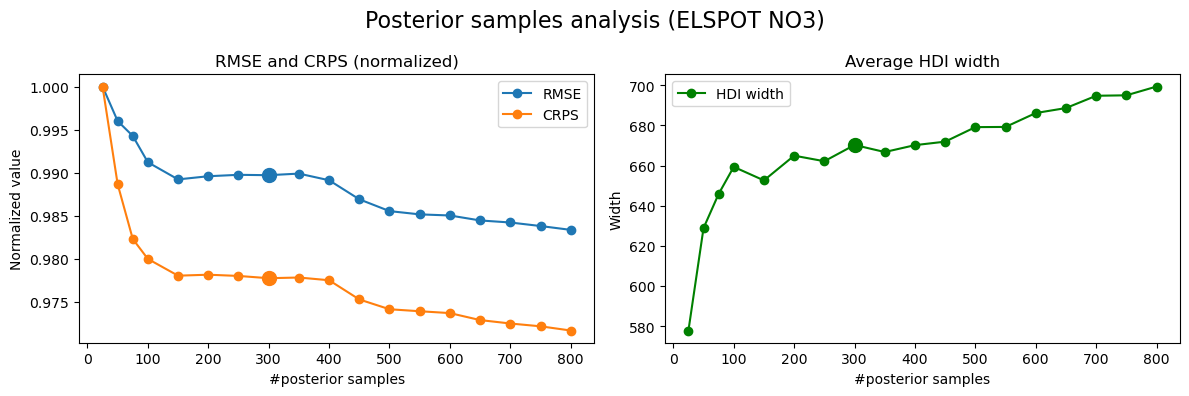

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Final value
idx = list(results["n_samples"]).index(300)

# Plot 1: RMSE + CRPS
axes[0].plot(
    results["n_samples"],
    results["RMSE"] / results["RMSE"].max(),
    marker="o",
    label="RMSE",
)
axes[0].plot(
    results["n_samples"],
    results["CRPS"] / results["CRPS"].max(),
    marker="o",
    label="CRPS",
)

# Highlight final setup
axes[0].scatter(
    results["n_samples"][idx],
    (results["RMSE"] / results["RMSE"].max())[idx],
    s=100,
    zorder=3,
)
axes[0].scatter(
    results["n_samples"][idx],
    (results["CRPS"] / results["CRPS"].max())[idx],
    s=100,
    zorder=3,
)

axes[0].set_title("RMSE and CRPS (normalized)")
axes[0].set_xlabel("#posterior samples")
axes[0].set_ylabel("Normalized value")
axes[0].legend()

# Plot 2: HDI width
axes[1].plot(
    results["n_samples"],
    results["HDI width"],
    marker="o",
    label="HDI width",
    color="green",
)
# Highlight final setup
axes[1].scatter(
    results["n_samples"][idx], results["HDI width"][idx], s=100, zorder=3, color="green"
)
axes[1].set_title("Average HDI width")
axes[1].set_xlabel("#posterior samples")
axes[1].set_ylabel("Width")
axes[1].legend()

fig.suptitle(f"Posterior samples analysis ({model_cfg.data.bid_zone})", fontsize=16)

plt.tight_layout()
plt.savefig("../plots/posterior_samples.pdf")